# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [1]:
import plotly.io as pio
pio.renderers.default = 'plotly_mimetype+png'

import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)

# Course palette from Lecture 7 (safe for colour vision deficiency)
BLUE, ORANGE = '#2E75B6', '#E07B39'
GREY, MID, LIGHT, DARK = '#AAAAAA', '#BBBBBB', '#DDDDDD', '#666666'
FONT = dict(family='Arial', size=13)

(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

- **Line chart** because years are continuous and the question is about growth over time. Every continent is divided by its own 1970 population so small and big continents can be compared on one scale. The x axis uses real years so the uneven gaps after 2010 keep their true spacing.
- **Grey with one highlight.** Africa grew the fastest so it is the only thick blue line and the other five stay thin and grey. This avoids the spaghetti problem from Lecture 3.
- **Labels instead of a legend.** Each line has its name and growth at the end so the eye does not jump to a legend (Lecture 3). The subtitle explains the unit so I dropped the rotated y axis title and it adds that Europe grew the least at 1.13x.

Continent
Africa           3.90
Oceania          2.31
South America    2.26
Asia             2.20
North America    1.90
Europe           1.13


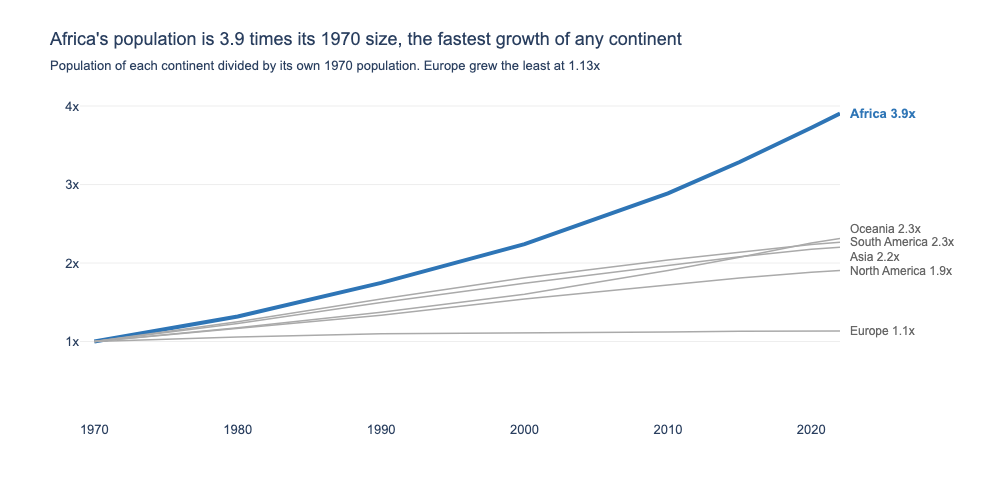

In [2]:
# Q1
# total population per continent and year, divided by its own 1970 value
continents = df_long.groupby(['Continent', 'Year'], as_index=False)['Population'].sum()
base_1970 = continents.loc[continents['Year'] == 1970].set_index('Continent')['Population']
continents['Growth'] = continents['Population'] / continents['Continent'].map(base_1970)

growth_2022 = (continents.loc[continents['Year'] == 2022]
               .set_index('Continent')['Growth'].sort_values(ascending=False))
fastest, slowest = growth_2022.index[0], growth_2022.index[-1]
print(growth_2022.round(2).to_string())

colour_map = {c: BLUE if c == fastest else GREY for c in growth_2022.index}

fig = px.line(
    data_frame=continents,
    x='Year', y='Growth',
    color='Continent',
    color_discrete_map=colour_map,
    hover_name='Continent',
    hover_data={'Continent': False, 'Growth': ':.1f', 'Population': ':,'},
    labels={'Growth': 'Population compared to 1970'},
    template='plotly_white',
    height=500, width=1000
)

# thin grey lines for context and one thick blue line for the story
fig.update_traces(line=dict(width=1.5))
fig.update_traces(line=dict(width=4), selector=dict(name=fastest))

fig.update_layout(
    title=dict(
        text=f"{fastest}'s population is {growth_2022[fastest]:.1f} times its 1970 size, the fastest growth of any continent",
        subtitle=dict(text=f'Population of each continent divided by its own 1970 population. '
                           f'{slowest} grew the least at {growth_2022[slowest]:.2f}x')
    ),
    font=FONT,
    showlegend=False,
    xaxis=dict(title='', showgrid=False, dtick=10, range=[1969, 2022]),
    # whole multiples only, the subtitle explains the unit so no rotated axis title is needed
    yaxis=dict(title='', gridcolor='#EEEEEE', zeroline=False, range=[0, growth_2022.max() + 0.3],
               tickvals=list(range(1, int(growth_2022.max()) + 2)),
               ticktext=[f'{v}x' for v in range(1, int(growth_2022.max()) + 2)]),
    margin=dict(r=160, t=90)
)

# direct labels at the end of each line instead of a legend
nudge = {'Oceania': 10, 'Asia': -10}   # these three lines end almost on top of each other
for continent, growth in growth_2022.items():
    is_fastest = continent == fastest
    fig.add_annotation(
        x=2022, y=growth,
        text=f'<b>{continent} {growth:.1f}x</b>' if is_fastest else f'{continent} {growth:.1f}x',
        showarrow=False, xanchor='left', xshift=8, yshift=nudge.get(continent, 0),
        font=dict(color=BLUE if is_fastest else DARK, size=13 if is_fastest else 12)
    )

fig.show()
fig.write_image('q1_continent_growth.png', scale=2)

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

- **Sorted horizontal bar chart** because the question asks for a ranking. Following Lecture 2 the bars start at zero, are sorted by value and the long country names fit on the side.
- **Africa is the only colour.** The question is about Africa so its 4 countries are blue and everything else is grey. The word Africa in the title has the same blue and works as the legend.
- **Values on the bars** so the x axis is not needed and I hid it. The subtitle adds that India and China alone added 1.46 billion.

      Country     Continent  Added_M
        India          Asia    859.7
        China          Asia    603.4
     Pakistan          Asia    176.5
      Nigeria        Africa    163.0
    Indonesia          Asia    160.3
United States North America    138.0
       Brazil South America    118.9
   Bangladesh          Asia    103.6
     Ethiopia        Africa     95.1
     DR Congo        Africa     78.9
  Philippines          Asia     78.1
       Mexico North America     77.2
        Egypt        Africa     76.2
         Iran          Asia     60.1
      Vietnam          Asia     56.3
African countries in the top 15: 4


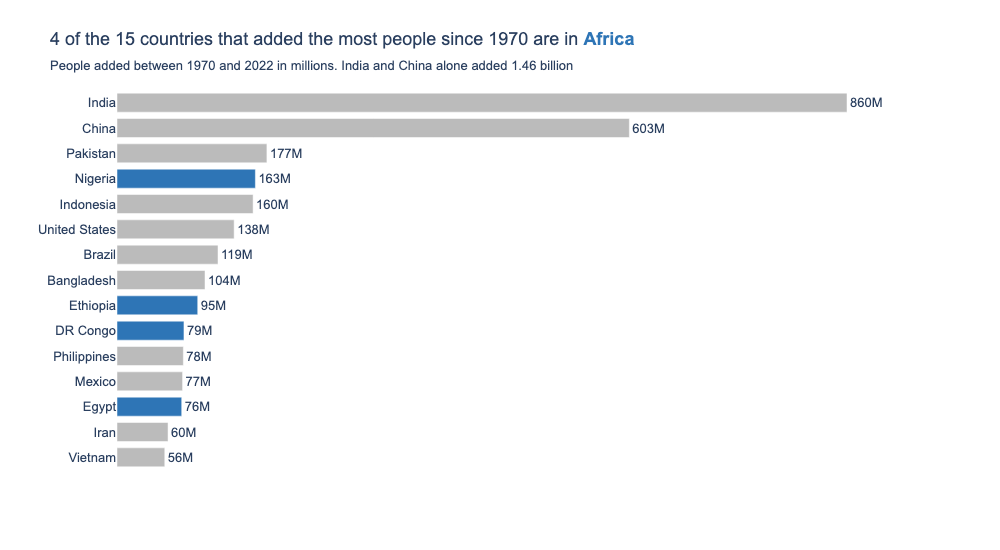

In [3]:
# Q2
df['Added'] = df['2022 Population'] - df['1970 Population']
top15 = df.nlargest(15, 'Added').copy()
top15['Added_M'] = top15['Added'] / 1e6
top15['Group'] = np.where(top15['Continent'] == 'Africa', 'Africa', 'Other')

n_africa = (top15['Group'] == 'Africa').sum()
india_china = top15.loc[top15['Country'].isin(['India', 'China']), 'Added'].sum()
print(top15[['Country', 'Continent', 'Added_M']].round(1).to_string(index=False))
print(f'African countries in the top 15: {n_africa}')

fig = px.bar(
    data_frame=top15,
    x='Added_M', y='Country',
    orientation='h',
    color='Group',
    color_discrete_map={'Africa': BLUE, 'Other': MID},
    text='Added_M',
    category_orders={'Country': top15['Country'].tolist()},   # biggest at the top
    hover_name='Country',
    hover_data={'Country': False, 'Group': False, 'Continent': True, 'Added_M': ':,.0f'},
    labels={'Added_M': 'People added since 1970 (millions)', 'Country': ''},
    template='plotly_white',
    height=550, width=1000
)

fig.update_traces(texttemplate='%{x:,.0f}M', textposition='outside', cliponaxis=False)

fig.update_layout(
    title=dict(
        text=f"{n_africa} of the 15 countries that added the most people since 1970 "
             f"are in <span style='color:{BLUE}'><b>Africa</b></span>",
        subtitle=dict(text=f'People added between 1970 and 2022 in millions. '
                           f'India and China alone added {india_china / 1e9:.2f} billion')
    ),
    font=FONT,
    showlegend=False,
    bargap=0.25,
    xaxis=dict(visible=False, range=[0, top15['Added_M'].max() * 1.1]),   # bars start at zero
    yaxis=dict(title=''),
    margin=dict(t=90)
)

fig.show()
fig.write_image('q2_people_added.png', scale=2)

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

- **Scatter plot** because area and population are two numbers and the question is about how they relate. Both axes are on a log scale because area goes from 1 km² to 17 million km² and population from about 500 to 1.4 billion. Without it almost every dot would sit in one corner (Lecture 4).
- **Dashed trend line as the reference** as Lecture 4 suggests. Dots above it have more people than their size predicts. Land does not create people by itself so I read it as a pattern and not a cause.
- **Asia is the only colour** because 78% of Asian countries sit above the line, more than any other continent. At the other end only 1 of 23 countries in Oceania sits above it. The blue word Asian in the title replaces the legend.
- **Labels only on outliers** (Lecture 4). Macau, Singapore and Bangladesh are among the four furthest above the line and Greenland, the Falklands and Iceland among the six furthest below. Hover shows the name and numbers for every other dot.

Correlation on log scale r = 0.87
Continent
Oceania          0.04
South America    0.21
Africa           0.51
North America    0.55
Europe           0.60
Asia             0.78


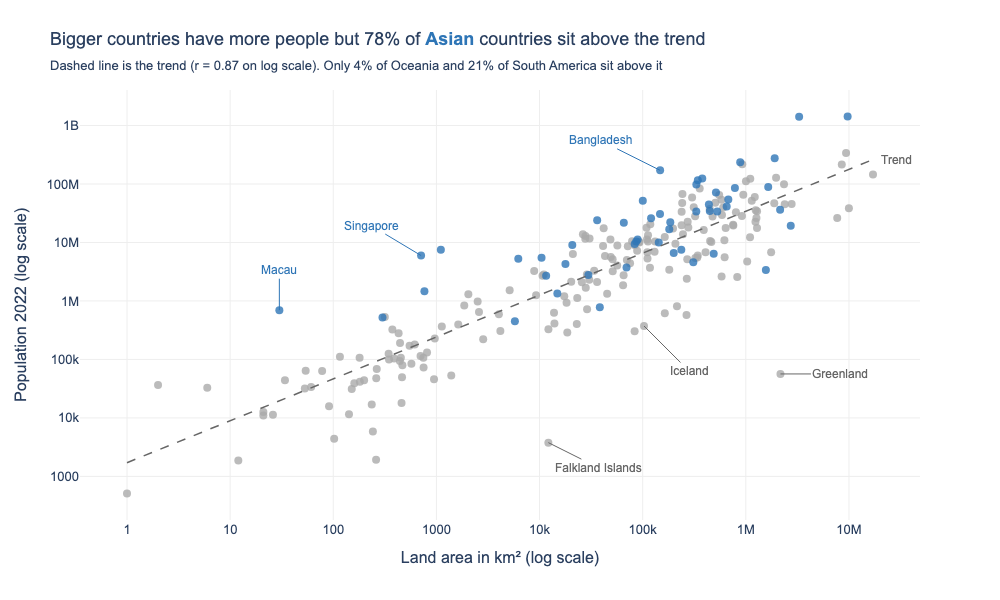

In [4]:
# Q3
d3 = df.copy()
d3['Group'] = np.where(d3['Continent'] == 'Asia', 'Asia', 'Other')

# same trend as the line on the chart, fitted on log scale
log_area, log_pop = np.log10(d3['Area']), np.log10(d3['2022 Population'])
slope, intercept = np.polyfit(log_area, log_pop, 1)
d3['Above trend'] = log_pop > intercept + slope * log_area
share_above = d3.groupby('Continent')['Above trend'].mean().sort_values()
r = np.corrcoef(log_area, log_pop)[0, 1]
print(f'Correlation on log scale r = {r:.2f}')
print(share_above.round(2).to_string())

fig = px.scatter(
    data_frame=d3,
    x='Area', y='2022 Population',
    color='Group',
    color_discrete_map={'Asia': BLUE, 'Other': GREY},
    category_orders={'Group': ['Other', 'Asia']},   # Asia drawn last so it sits on top
    log_x=True, log_y=True,
    trendline='ols', trendline_scope='overall',
    trendline_options=dict(log_x=True, log_y=True),
    trendline_color_override=DARK,
    hover_name='Country',
    hover_data={'Group': False, 'Continent': True, 'Area': ':,', '2022 Population': ':,', 'Density': ':,.0f'},
    labels={'Area': 'Land area in km² (log scale)', '2022 Population': 'Population 2022 (log scale)',
            'Density': 'People per km²'},
    template='plotly_white',
    height=600, width=1000
)

fig.update_traces(selector=dict(mode='markers'), marker=dict(size=8, opacity=0.8))
fig.update_traces(selector=dict(mode='lines'), line=dict(width=1.5, dash='dash'))

fig.update_layout(
    title=dict(
        text=f"Bigger countries have more people but {share_above['Asia']:.0%} of "
             f"<span style='color:{BLUE}'><b>Asian</b></span> countries sit above the trend",
        subtitle=dict(text=f"Dashed line is the trend (r = {r:.2f} on log scale). "
                           f"Only {share_above['Oceania']:.0%} of Oceania and "
                           f"{share_above['South America']:.0%} of South America sit above it")
    ),
    font=FONT,
    showlegend=False,
    xaxis=dict(gridcolor='#EEEEEE'),
    yaxis=dict(gridcolor='#EEEEEE'),
    margin=dict(t=90)
)

# label only countries that sit far from the trend line
outliers = {'Macau': (0, -40), 'Singapore': (-50, -30), 'Bangladesh': (-60, -30),
            'Greenland': (60, 0), 'Falkland Islands': (50, 25), 'Iceland': (45, 45)}
for country, (ax, ay) in outliers.items():
    row = d3.loc[d3['Country'] == country].iloc[0]
    colour = BLUE if row['Group'] == 'Asia' else DARK
    fig.add_annotation(
        x=np.log10(row['Area']), y=np.log10(row['2022 Population']),   # log axes need log10 positions
        text=country, showarrow=True, arrowhead=0, arrowcolor=colour, ax=ax, ay=ay,
        font=dict(size=12, color=colour)
    )

max_area = d3['Area'].max()
fig.add_annotation(x=np.log10(max_area), y=intercept + slope * np.log10(max_area),
                   text='Trend', showarrow=False, xanchor='left', xshift=6,
                   font=dict(size=12, color=DARK))

fig.show()
fig.write_image('q3_area_vs_population.png', scale=2)

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

- **Box plot** because it compares the spread of several groups in a compact way (Lecture 5). A violin needs more points to show a real shape and South America has only 14 countries.
- **Log scale** because density goes from 0.03 to over 23,000 people per km². The boxes are drawn on the log values so the whiskers match what the axis shows.
- **Shape named in the title** as Lecture 5 asks. Most countries sit in the middle and city states like Macau, Monaco and Singapore form a long tail of very crowded places. The subtitle backs the title up with 85% of the variation being inside the continents.
- **Dots and a median line.** Every country is a dot on its box so the reader sees the whole spread and not only the average. The dashed line is the world median of 95 to compare the continents against.
- **Asia is blue** because it has the most extreme points on both ends. Macau is the most crowded place in the data and Mongolia is the fourth emptiest. The continents are named on the axis so no legend is needed.

Continent
North America    221.0
Asia             123.0
Europe           107.0
Oceania           78.0
Africa            60.0
South America     18.0
World median 95, variation within continents 85%, densest ['Macau', 'Monaco', 'Singapore']


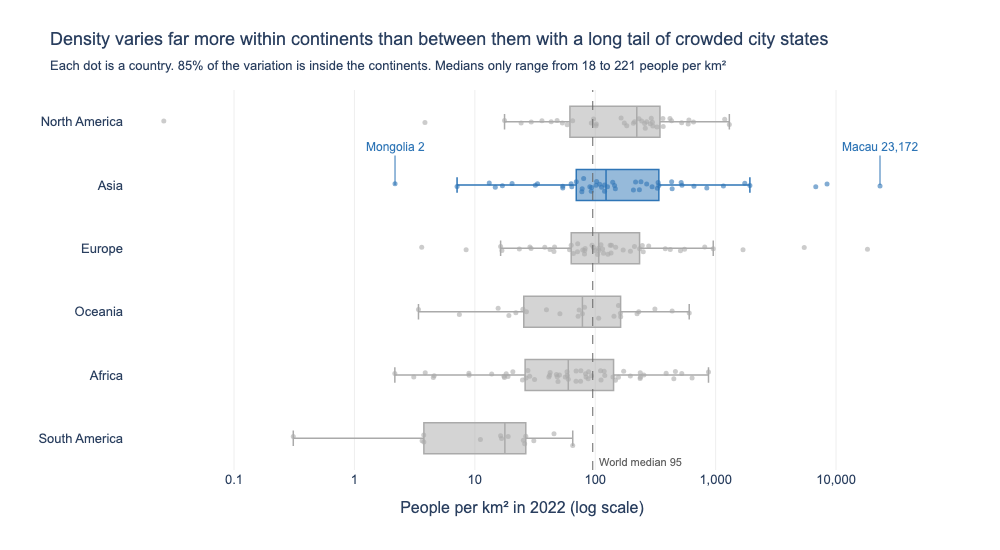

In [5]:
# Q4
d4 = df.copy()
# boxes are drawn on log10 values so the whiskers are computed on the same scale the axis shows
d4['Log density'] = np.log10(d4['Density'])

medians = d4.groupby('Continent')['Density'].median().sort_values(ascending=False)
order = medians.index.tolist()   # highest median at the top
world_median = d4['Density'].median()

# share of the variation (on the log scale) that is inside the continents and not between them
continent_mean = d4.groupby('Continent')['Log density'].transform('mean')
within_share = (((d4['Log density'] - continent_mean) ** 2).sum()
                / ((d4['Log density'] - d4['Log density'].mean()) ** 2).sum())

asia = d4.loc[d4['Continent'] == 'Asia']
asia_min = asia.loc[asia['Density'].idxmin()]
asia_max = asia.loc[asia['Density'].idxmax()]
city_states = d4.nlargest(3, 'Density')['Country'].tolist()
print(medians.round(0).to_string())
print(f'World median {world_median:.0f}, variation within continents {within_share:.0%}, densest {city_states}')

fig = px.box(
    data_frame=d4,
    x='Log density', y='Continent',
    orientation='h',
    color='Continent',
    color_discrete_map={c: BLUE if c == 'Asia' else GREY for c in order},
    category_orders={'Continent': order},
    points='all',   # every country is a dot so the spread is visible
    hover_name='Country',
    hover_data={'Continent': False, 'Log density': False, 'Density': ':,.2~f'},
    labels={'Density': 'People per km²', 'Continent': ''},
    template='plotly_white',
    height=550, width=1000
)

fig.update_traces(jitter=0.5, pointpos=0, marker=dict(size=5, opacity=0.6), line=dict(width=1.5),
                  hoveron='points')   # hover on a dot shows the real density, not the log value

ticks = list(range(-1, 5))
fig.update_layout(
    title=dict(
        text='Density varies far more within continents than between them with a long tail of crowded city states',
        subtitle=dict(text=f"Each dot is a country. {within_share:.0%} of the variation is inside the continents. "
                           f"Medians only range from {medians.min():.0f} to {medians.max():.0f} people per km²")
    ),
    font=FONT,
    showlegend=False,
    xaxis=dict(title='People per km² in 2022 (log scale)', gridcolor='#EEEEEE', zeroline=False,
               tickvals=ticks, ticktext=[f'{10 ** t:,.10g}' for t in ticks]),
    yaxis=dict(showgrid=False),
    margin=dict(t=90)
)

# world median as the reference line
fig.add_vline(x=np.log10(world_median), line_dash='dash', line_color=DARK, line_width=1)
fig.add_annotation(x=np.log10(world_median), y=0, yref='paper', xanchor='left', yanchor='bottom', xshift=4,
                   text=f'World median {world_median:.0f}', showarrow=False, font=dict(color=DARK, size=11))

# the two ends of Asia
for row in [asia_min, asia_max]:
    fig.add_annotation(x=np.log10(row['Density']), y='Asia',
                       text=f"{row['Country']} {row['Density']:,.0f}",
                       showarrow=True, arrowhead=0, arrowcolor=BLUE, ax=0, ay=-38,
                       font=dict(size=12, color=BLUE))

fig.show()
fig.write_image('q4_density_spread.png', scale=2)

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

- **Choropleth map** because the question asks where in the world it happened so location is the story (Lecture 6).
- **Diverging scale** because change has a real midpoint at zero (Lecture 6). Orange means shrank and blue means grew which stays readable for colour blind people unlike red and green (Lecture 7). The colour legend stays because a map needs it.
- **Capped at 25% both ways** because Qatar grew 317% and would make the shrinking European countries look almost white. The cap is written under the map as Lecture 5 asks.
- **Labels in the ocean** give the answer on the static image. Europe has 18 of the 34 places that shrank and every African country grew. Most of the other 16 are islands too small to see so the note under the map names where they are. Hover gives the exact change for every country.

Continent
Europe           18
North America     7
Oceania           6
Asia              3
                         Country     Continent
                  American Samoa       Oceania
                         Armenia          Asia
                         Georgia          Asia
                      Guadeloupe North America
                           Japan          Asia
                Marshall Islands       Oceania
                      Martinique North America
                      Montserrat North America
                            Niue       Oceania
        Northern Mariana Islands       Oceania
                           Palau       Oceania
                     Puerto Rico North America
       Saint Pierre and Miquelon North America
Saint Vincent and the Grenadines North America
    United States Virgin Islands North America
               Wallis and Futuna       Oceania
Grew 200, shrank 34, biggest growth Qatar +317%


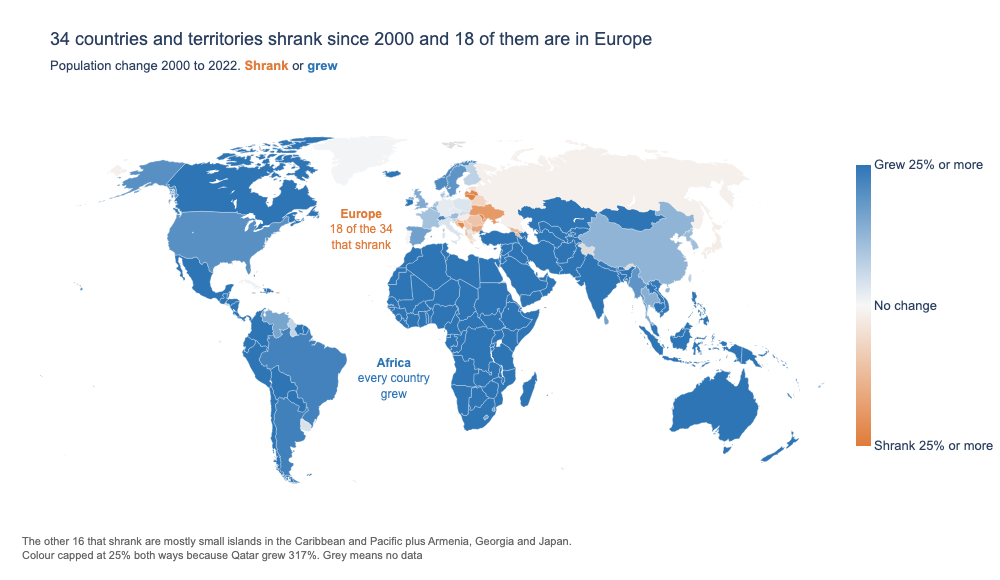

In [6]:
# Q5
df['Change'] = (df['2022 Population'] / df['2000 Population'] - 1) * 100
shrank = df.loc[df['Change'] < 0]
n_shrank = len(shrank)
shrank_by_continent = shrank['Continent'].value_counts()
n_europe = shrank_by_continent.get('Europe', 0)
n_africa_shrank = shrank_by_continent.get('Africa', 0)
asia_names = sorted(shrank.loc[shrank['Continent'] == 'Asia', 'Country'])
asia_list = ', '.join(asia_names[:-1]) + ' and ' + asia_names[-1]
top = df.loc[df['Change'].idxmax()]
print(shrank_by_continent.to_string())
print(shrank.loc[~shrank['Continent'].isin(['Europe']), ['Country', 'Continent']].to_string(index=False))
print(f"Grew {(df['Change'] > 0).sum()}, shrank {n_shrank}, biggest growth {top['Country']} {top['Change']:+.0f}%")

CAP = 25   # Qatar grew 317% and would wash out every other country

fig = px.choropleth(
    data_frame=df,
    locations='CCA3', locationmode='ISO-3',
    color='Change',
    color_continuous_scale=[ORANGE, '#F7F7F7', BLUE],   # diverging, white at zero
    range_color=[-CAP, CAP],
    hover_name='Country',
    hover_data={'CCA3': False, 'Change': ':+.1f', '2000 Population': ':,', '2022 Population': ':,'},
    labels={'Change': 'Change 2000 to 2022 (%)'},
    projection='natural earth',
    template='plotly_white',
    height=580, width=1000
)

fig.update_traces(marker_line_color='white', marker_line_width=0.3)

fig.update_layout(
    title=dict(
        text=f"{n_shrank} countries and territories shrank since 2000 and {n_europe} of them are in Europe",
        subtitle=dict(text=f"Population change 2000 to 2022. "
                           f"<span style='color:{ORANGE}'><b>Shrank</b></span> or "
                           f"<span style='color:{BLUE}'><b>grew</b></span>")
    ),
    font=FONT,
    geo=dict(showframe=False, showcoastlines=False, showland=True, landcolor=LIGHT,
             lataxis_range=[-58, 85]),   # crop Antarctica
    # the tick labels say what each colour means so the colour legend needs no separate title
    coloraxis_colorbar=dict(title='', thickness=15, len=0.7,
                            tickvals=[-CAP, 0, CAP],
                            ticktext=[f'Shrank {CAP}% or more', 'No change', f'Grew {CAP}% or more']),
    margin=dict(l=20, r=0, t=90, b=60)
)

# answer written in the ocean next to each continent
fig.add_scattergeo(lon=[-31], lat=[42], mode='text',
                   text=[f'<b>Europe</b><br>{n_europe} of the {n_shrank}<br>that shrank'],
                   textfont=dict(color=ORANGE, size=12), hoverinfo='skip', showlegend=False)
fig.add_scattergeo(lon=[-14], lat=[-15], mode='text',
                   text=['<b>Africa</b><br>every country<br>grew' if n_africa_shrank == 0 else '<b>Africa</b>'],
                   textfont=dict(color=BLUE, size=12), hoverinfo='skip', showlegend=False)

fig.add_annotation(
    xref='paper', yref='paper', x=0, y=-0.03, xanchor='left', yanchor='top', showarrow=False, align='left',
    text=f"The other {n_shrank - n_europe} that shrank are mostly small islands in the Caribbean and Pacific "
         f"plus {asia_list}.<br>Colour capped at {CAP}% both ways because {top['Country']} grew "
         f"{top['Change']:.0f}%. Grey means no data",
    font=dict(size=11, color=DARK)
)

fig.show()
fig.write_image('q5_growth_map.png', scale=2)

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

- **Treemap** because the data has two levels and Lecture 7 suggests a treemap for size inside a hierarchy with many parts. All 234 countries fit in one view and box size is population.
- **Only Asian countries are blue.** Asia holds most of the world's people so it is the only colour and the continent boxes stay light grey like in Lecture 7. The blue word Asia in the title works as the legend.
- **Shares written in the boxes** so the continents and big countries can be read on the static image, for example India and China at about 18% each. Oceania is too thin to read so the subtitle names it. Hover gives the exact population for the tiny boxes.

World population 7,973,413,042
Continent
Asia             0.592
Africa           0.179
Europe           0.093
North America    0.075
South America    0.055
Oceania          0.006
India and China together 35.7%


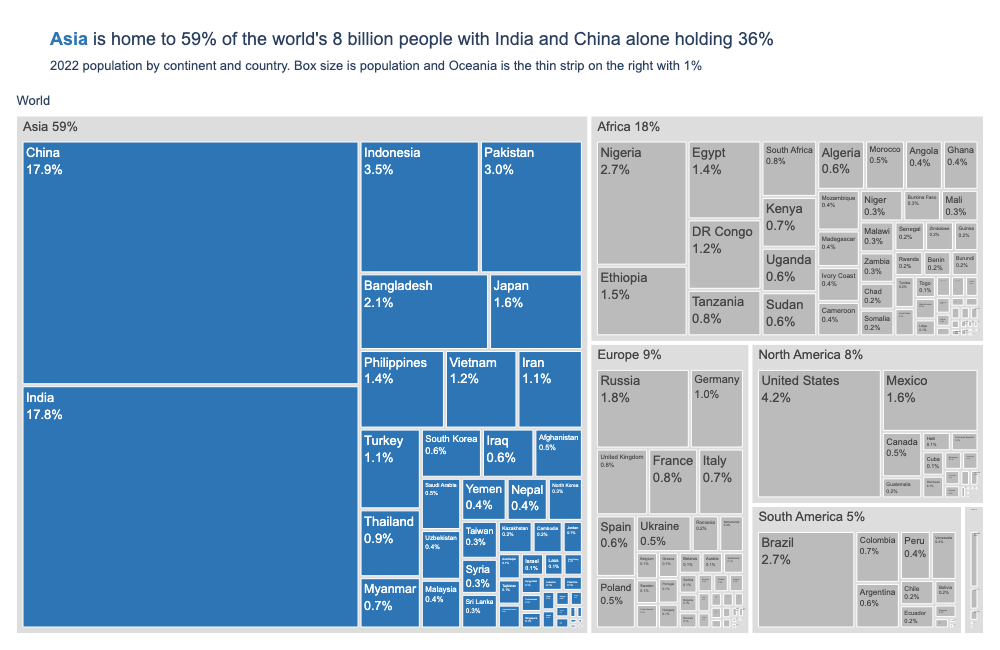

In [7]:
# Q6
world = df['2022 Population'].sum()
continent_share = df.groupby('Continent')['2022 Population'].sum().sort_values(ascending=False) / world
india_china = df.loc[df['Country'].isin(['India', 'China']), '2022 Population'].sum() / world
print(f'World population {world:,.0f}')
print(continent_share.round(3).to_string())
print(f'India and China together {india_china:.1%}')

d6 = df.copy()
d6['Group'] = np.where(d6['Continent'] == 'Asia', 'Asia', 'Other')
# the continent header only shows its name, so the share goes into the name itself
d6['Continent share'] = d6['Continent'] + ' ' + d6['Continent'].map(continent_share).map('{:.0%}'.format)
colours = {'Asia': BLUE, 'Other': MID}

fig = px.treemap(
    data_frame=d6,
    path=[px.Constant('World'), 'Continent share', 'Country'],
    values='2022 Population',
    color='Group',
    color_discrete_map=colours,
    template='plotly_white',
    height=650, width=1000
)

fig.update_traces(
    texttemplate='%{label}<br>%{percentRoot:.1%}',
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} people<br>%{percentRoot:.1%} of the world<extra></extra>',
    root_color='white',
    marker=dict(line=dict(color='white', width=1))
)

fig.update_layout(
    title=dict(
        text=f"<span style='color:{BLUE}'><b>Asia</b></span> is home to {continent_share['Asia']:.0%} of the "
             f"world's {world / 1e9:.0f} billion people with India and China alone holding {india_china:.0%}",
        subtitle=dict(text=f"2022 population by continent and country. Box size is population and Oceania "
                           f"is the thin strip on the right with {continent_share['Oceania']:.0%}")
    ),
    font=FONT,
    margin=dict(t=90, l=10, r=10, b=10)
)

# only the countries carry colour, continent boxes are light grey and the root is white
fig.data[0].marker.colors = [
    'white' if node == 'World' else LIGHT if node.count('/') == 1 else colour
    for node, colour in zip(fig.data[0].ids, fig.data[0].marker.colors)
]

fig.show()
fig.write_image('q6_population_treemap.png', scale=2)

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

- **100% stacked bar chart** because the question is about shares of one whole. Lecture 7 says 100% stacked bars fit when the mix is the story and 4 groups is inside its 2 to 5 segment range.
- **Africa on the zero baseline and Europe on top against 100%** so both groups that changed have a fixed edge and are easy to compare. Lecture 2 also puts the most important segment on the bottom.
- **Two accent colours** because the story has two sides. Blue for the share that rose and orange for the one that fell is the course pair that is safe for colour blind readers. Asia and the rest of the world are grey because they barely changed.
- **Direct labels instead of a legend** (Lecture 7). Shares are written on Africa and Europe and on Asia in the first and last year since the question asks about Asia too. The hidden y axis is replaced by a 100% mark and a note says the years are not evenly spaced.

Group  Africa  Asia  Europe  Rest of the world
Year                                          
1970      9.9  58.1    17.8               14.3
1980     10.8  59.3    15.6               14.2
1990     12.0  60.4    13.6               14.0
2000     13.3  60.8    11.8               14.1
2010     15.1  60.4    10.5               13.9
2015     16.2  60.0    10.0               13.8
2020     17.4  59.5     9.5               13.6
2022     17.9  59.2     9.3               13.6
Africa first above Europe in 2000


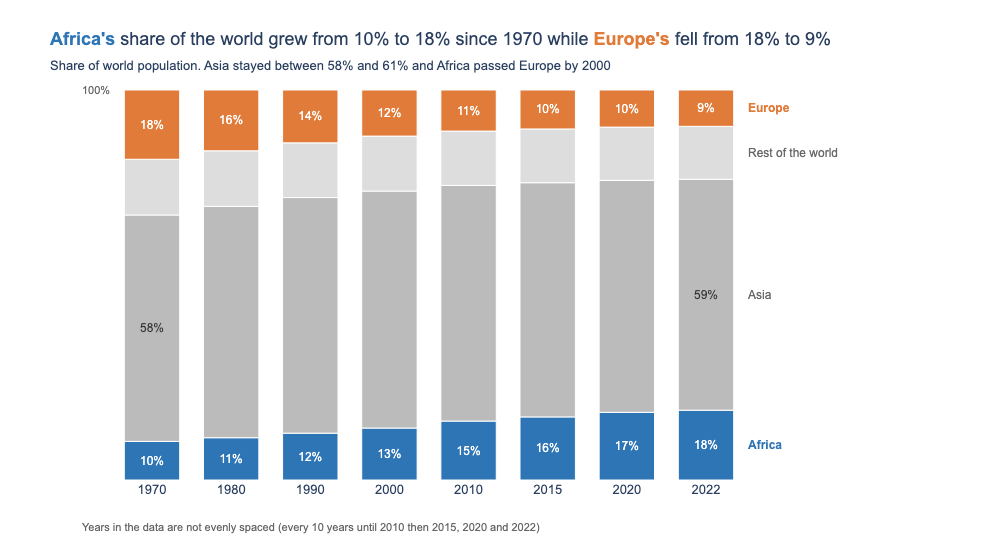

In [8]:
# Q7
groups = df_long.copy()
groups['Group'] = groups['Continent'].where(groups['Continent'].isin(['Africa', 'Asia', 'Europe']),
                                            'Rest of the world')
shares = groups.groupby(['Year', 'Group'], as_index=False)['Population'].sum()
shares['Share'] = shares['Population'] / shares.groupby('Year')['Population'].transform('sum')

pivot = shares.pivot(index='Year', columns='Group', values='Share')
first_year, last_year = pivot.index.min(), pivot.index.max()
crossover = pivot.index[pivot['Africa'] > pivot['Europe']].min()
print((pivot * 100).round(1).to_string())
print(f'Africa first above Europe in {crossover}')

group_order = ['Africa', 'Asia', 'Rest of the world', 'Europe']   # Africa on the baseline, Europe on top
colours = {'Africa': BLUE, 'Asia': MID, 'Rest of the world': LIGHT, 'Europe': ORANGE}
highlighted = ['Africa', 'Europe']

shares['Year'] = shares['Year'].astype(str)   # one bar per year in the data
# shares on the two accent groups, plus Asia on the first and last bar because the question asks about it
show_label = shares['Group'].isin(highlighted) | (
    (shares['Group'] == 'Asia') & shares['Year'].isin([str(first_year), str(last_year)]))
shares['Label'] = np.where(show_label, shares['Share'].map('{:.0%}'.format), '')

fig = px.bar(
    data_frame=shares,
    x='Year', y='Share',
    color='Group',
    color_discrete_map=colours,
    category_orders={'Group': group_order},
    text='Label',
    hover_name='Group',
    hover_data={'Group': False, 'Label': False, 'Share': ':.1%', 'Population': ':,'},
    labels={'Share': 'Share of world population'},
    template='plotly_white',
    height=550, width=1000
)

fig.update_traces(
    textposition='inside', insidetextanchor='middle',
    textfont=dict(color='white', size=12),
    marker_line_color='white', marker_line_width=1
)
fig.update_traces(selector=dict(name='Asia'), textfont_color='#333333')   # dark text on the grey segment

a0, a1 = pivot.loc[first_year, 'Africa'], pivot.loc[last_year, 'Africa']
e0, e1 = pivot.loc[first_year, 'Europe'], pivot.loc[last_year, 'Europe']
fig.update_layout(
    title=dict(
        text=f"<span style='color:{BLUE}'><b>Africa's</b></span> share of the world grew from {a0:.0%} to {a1:.0%} "
             f"since {first_year} while <span style='color:{ORANGE}'><b>Europe's</b></span> fell from {e0:.0%} to {e1:.0%}",
        subtitle=dict(text=f"Share of world population. Asia stayed between {pivot['Asia'].min():.0%} and "
                           f"{pivot['Asia'].max():.0%} and Africa passed Europe by {crossover}")
    ),
    font=FONT,
    showlegend=False,
    bargap=0.3,
    xaxis=dict(title='', type='category'),
    yaxis=dict(visible=False, range=[0, 1]),
    margin=dict(l=80, r=160, t=90, b=70)
)

# group names next to the last bar instead of a legend
last = pivot.loc[last_year, group_order]
middles = last.cumsum() - last / 2
last_bar = len(pivot) - 1   # on a category axis annotations use the bar position
for group in group_order:
    is_highlighted = group in highlighted
    fig.add_annotation(
        x=last_bar, y=middles[group],
        text=f'<b>{group}</b>' if is_highlighted else group,
        showarrow=False, xanchor='left', xshift=40,
        font=dict(size=12, color=colours[group] if is_highlighted else DARK)
    )

# the y axis is hidden so mark the top of the scale (Lecture 7)
fig.add_annotation(x=0, y=1, xanchor='right', xshift=-40, text='100%', showarrow=False,
                   font=dict(size=11, color=DARK))

fig.add_annotation(
    xref='paper', yref='paper', x=0, y=-0.1, xanchor='left', yanchor='top', showarrow=False,
    text='Years in the data are not evenly spaced (every 10 years until 2010 then 2015, 2020 and 2022)',
    font=dict(size=11, color=DARK)
)

fig.show()
fig.write_image('q7_world_share.png', scale=2)